# ICE Task 3 – Case Study: FIFA 18 Player Analysis
**Student number:** ST10365068

## Introduction
This case study explores the FIFA 18 complete player dataset (Kaggle: *FIFA 18 Complete Player Dataset*, used in the
"FIFA18 Analysis for Beginners" notebook). The dataset holds personal information (name, age, nationality, club, value, wage),
skill attributes (e.g. acceleration, finishing, vision) and position ratings for every player in the game.

**Objectives**
1. Import the data from the CSV file.
2. Create a `players` data frame with the columns **Name, Age, Club**.
3. Check for missing values – every player should have an age and a club.
4. Apply operations: sort (find the youngest players), filter on a particular team, find the teams with the highest wages,
   and group players by nationality.

## 1. Import libraries

In [1]:
#ST10365068
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 2. Import the data
`CompleteDataset.csv` combines the three separate files from the original dataset
(`PlayerPersonalData.csv`, `PlayerAttributeData.csv` and `PlayerPlayingPositionData.csv`) into one table.

In [2]:
#ST10365068
df = pd.read_csv("CompleteDataset.csv", low_memory=False)
df = df.drop(columns=["Unnamed: 0"])   # leftover index column from the export

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (15405, 74)


,ID,Photo,Name,Age,Nationality,Flag,Overall,Potential,Club,Club Logo,...,RB,RCB,RCM,RDM,RF,RM,RS,RW,RWB,ST
0,158023,https://cdn.sofifa.org/players/4/18/158023.png,L. Messi,30,Argentina,https://cdn.sofifa.org/flags/52.png,93,93,FC Barcelona,https://cdn.sofifa.org/24/18/teams/241.png,...,57.0,45.0,84.0,59.0,92.0,90.0,88.0,91.0,62.0,88.0
1,20801,https://cdn.sofifa.org/players/4/18/20801.png,Cristiano Ronaldo,32,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Real Madrid CF,https://cdn.sofifa.org/24/18/teams/243.png,...,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,92.0
2,190871,https://cdn.sofifa.org/players/4/18/190871.png,Neymar,25,Brazil,https://cdn.sofifa.org/flags/54.png,92,94,Paris Saint-Germain,https://cdn.sofifa.org/24/18/teams/73.png,...,59.0,46.0,79.0,59.0,88.0,87.0,84.0,89.0,64.0,84.0
3,176580,https://cdn.sofifa.org/players/4/18/176580.png,L. Suárez,30,Uruguay,https://cdn.sofifa.org/flags/60.png,92,92,FC Barcelona,https://cdn.sofifa.org/24/18/teams/241.png,...,64.0,58.0,80.0,65.0,88.0,85.0,88.0,87.0,68.0,88.0
4,167495,https://cdn.sofifa.org/players/4/18/167495.png,M. Neuer,31,Germany,https://cdn.sofifa.org/flags/21.png,92,92,FC Bayern Munich,https://cdn.sofifa.org/24/18/teams/21.png,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Check for duplicate players
Some players appear more than once (identical rows with the same `ID`), which would double-count them in totals.

In [3]:
#ST10365068
print("Duplicate rows:", df.duplicated(subset="ID").sum())
df = df.drop_duplicates(subset="ID").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Duplicate rows: 87
Rows after removing duplicates: 15318


The complete dataset can be split back into the three logical parts it was built from:

In [4]:
#ST10365068
personal_cols = ["ID", "Name", "Age", "Nationality", "Overall", "Potential", "Club", "Value", "Wage", "Special"]
position_cols = ["ID", "Preferred Positions", "CAM", "CB", "CDM", "CF", "CM", "LAM", "LB", "LCB", "LCM", "LDM",
                 "LF", "LM", "LS", "LW", "LWB", "RAM", "RB", "RCB", "RCM", "RDM", "RF", "RM", "RS", "RW", "RWB", "ST"]
attribute_cols = ["ID"] + [c for c in df.columns
                           if c not in personal_cols + position_cols + ["Photo", "Flag", "Club Logo"]]

player_personal = df[personal_cols]
player_attributes = df[attribute_cols]
player_positions = df[position_cols]

print("Personal data:  ", player_personal.shape)
print("Attribute data: ", player_attributes.shape)
print("Position data:  ", player_positions.shape)

Personal data:   (15318, 10)
Attribute data:  (15318, 35)
Position data:   (15318, 28)


In [5]:
#ST10365068
df.info(verbose=False)
df[["Age", "Overall", "Potential"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 15318 entries, 0 to 15317
Columns: 74 entries, ID to ST
dtypes: float64(26), int64(5), str(43)
memory usage: 8.6 MB


,Age,Overall,Potential
count,15318.000000,15318.000000,15318.000000
mean,25.136049,66.761196,71.649563
std,4.516590,6.834784,6.059448
min,16.000000,46.000000,48.000000
25%,22.000000,62.000000,67.000000
50%,25.000000,67.000000,71.000000
75%,28.000000,71.000000,75.000000
max,44.000000,94.000000,94.000000


## 3. Create the `players` data frame (Name, Age, Club)

In [6]:
#ST10365068
players = df[["Name", "Age", "Club"]]
players.head(10)

,Name,Age,Club
0,L. Messi,30,FC Barcelona
1,Cristiano Ronaldo,32,Real Madrid CF
2,Neymar,25,Paris Saint-Germain
3,L. Suárez,30,FC Barcelona
4,M. Neuer,31,FC Bayern Munich
5,De Gea,26,Manchester United
6,K. De Bruyne,26,Manchester City
7,R. Lewandowski,28,FC Bayern Munich
8,E. Hazard,26,Chelsea
9,T. Kroos,27,Real Madrid CF


## 4. Check for missing values
Every player should have an **Age** and a **Club** entered.

In [7]:
#ST10365068
players.isnull().sum()

Name      0
Age       0
Club    172
dtype: int64

In [8]:
#ST10365068
missing_club = players[players["Club"].isnull()]
print(f"{len(missing_club)} players have no club ({len(missing_club) / len(players):.2%} of the dataset)")
missing_club.head(10)

172 players have no club (1.12% of the dataset)


,Name,Age,Club
246,Oscar,25,NaN
250,Adrien Silva,28,NaN
262,A. Witsel,28,NaN
481,M. Berg,30,NaN
495,Renato Augusto,29,NaN
842,Gervinho,30,NaN
854,B. Moukandjo,28,NaN
1155,C. Riveros,34,NaN
1511,T. Hlatshwayo,27,NaN
1542,B. Dočkal,28,NaN


All players have an age, but some have no club. These are **free agents** (not contracted to any team),
so they cannot be used in club-based analysis. They are removed to create a clean data frame.

In [9]:
#ST10365068
players_clean = players.dropna(subset=["Age", "Club"]).copy()
print("Before cleaning:", players.shape)
print("After cleaning: ", players_clean.shape)
players_clean.isnull().sum()

Before cleaning: (15318, 3)
After cleaning:  (15146, 3)


Name    0
Age     0
Club    0
dtype: int64

## 5. Sort – youngest (and oldest) players

In [10]:
#ST10365068
youngest = players_clean.sort_values(by="Age").head(10)
youngest

,Name,Age,Club
11241,L. Geertruida,16,Feyenoord
13608,G. McEachran,16,Chelsea
10666,A. Gomes,16,Manchester United
6974,K. Pierie,16,SC Heerenveen
9220,E. Håland,16,Molde FK
12620,E. Vignato,16,Chievo Verona
14839,R. Strechie,16,F.B.C. Unione Venezia
14844,L. Pintor,16,Stade Brestois 29
14036,M. Sprang,16,FSV Zwickau
13955,Javi Vázquez,16,Sevilla Atlético


In [11]:
#ST10365068
oldest = players_clean.sort_values(by="Age", ascending=False).head(10)
oldest

,Name,Age,Club
4951,E. El Hadary,44,Al Taawoun
4509,O. Pérez,44,Pachuca
14314,C. Day,41,Stevenage
7332,K. Wæhler,41,Sogndal
12695,M. Tyler,40,Peterborough United
3086,M. Candelo,40,Asociacion Deportivo Cali
2678,B. Nivet,40,ES Troyes AC
1295,M. Storari,40,Milan
3624,T. Simons,40,Club Brugge KV
10599,F. Kippe,39,Lillestrøm SK


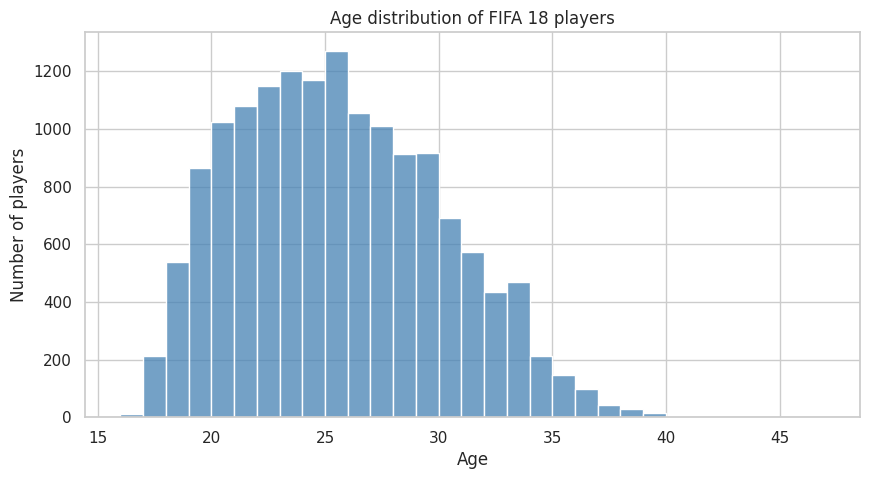

Mean age:   25.1
Median age: 25.0


In [12]:
#ST10365068
plt.figure(figsize=(10, 5))
sns.histplot(players_clean["Age"], bins=range(16, 48), color="steelblue")
plt.title("Age distribution of FIFA 18 players")
plt.xlabel("Age")
plt.ylabel("Number of players")
plt.show()

print("Mean age:  ", round(players_clean["Age"].mean(), 1))
print("Median age:", players_clean["Age"].median())

## 6. Filter on a particular team
Example: all players at **Manchester United**, sorted by age.

In [13]:
#ST10365068
def get_team(team_name):
    return players_clean[players_clean["Club"] == team_name].sort_values(by="Age")

man_utd = get_team("Manchester United")
print("Squad size:", len(man_utd))
print("Average age:", round(man_utd["Age"].mean(), 1))
man_utd

Squad size: 32
Average age: 24.3


,Name,Age,Club
10666,A. Gomes,16,Manchester United
10697,C. Gribbin,18,Manchester United
12262,Z. Dearnley,18,Manchester United
276,M. Rashford,19,Manchester United
2617,A. Tuanzebe,19,Manchester United
9292,D. Mitchell,20,Manchester United
8897,J. Riley,20,Manchester United
7005,S. McTominay,20,Manchester United
737,L. Shaw,21,Manchester United
156,A. Martial,21,Manchester United


In [14]:
#ST10365068
# the same filter is reusable for any club
get_team("FC Barcelona").head()

,Name,Age,Club
148,O. Dembélé,20,FC Barcelona
277,Nélson Semedo,23,FC Barcelona
111,S. Umtiti,23,FC Barcelona
215,André Gomes,23,FC Barcelona
302,Deulofeu,23,FC Barcelona


## 7. Teams with the highest wages
`Wage` and `Value` are stored as text (e.g. `€565K`, `€105M`), so they are converted to numbers in euros first.

In [15]:
#ST10365068
def money_to_number(text):
    text = str(text).replace("€", "").strip()
    if text.endswith("M"):
        return float(text[:-1]) * 1_000_000
    if text.endswith("K"):
        return float(text[:-1]) * 1_000
    return float(text)

df["Wage_EUR"] = df["Wage"].apply(money_to_number)
df["Value_EUR"] = df["Value"].apply(money_to_number)
df[["Name", "Club", "Wage", "Wage_EUR", "Value", "Value_EUR"]].head()

,Name,Club,Wage,Wage_EUR,Value,Value_EUR
0,L. Messi,FC Barcelona,€565K,565000.0,€105M,105000000.0
1,Cristiano Ronaldo,Real Madrid CF,€565K,565000.0,€95.5M,95500000.0
2,Neymar,Paris Saint-Germain,€280K,280000.0,€123M,123000000.0
3,L. Suárez,FC Barcelona,€510K,510000.0,€97M,97000000.0
4,M. Neuer,FC Bayern Munich,€230K,230000.0,€61M,61000000.0


In [16]:
#ST10365068
clubs = df.dropna(subset=["Club"])

club_wages = (clubs.groupby("Club")
                   .agg(Total_Weekly_Wage=("Wage_EUR", "sum"),
                        Average_Wage=("Wage_EUR", "mean"),
                        Squad_Size=("Name", "count"),
                        Average_Overall=("Overall", "mean"))
                   .sort_values(by="Total_Weekly_Wage", ascending=False))

top_wage_clubs = club_wages.head(10)
top_wage_clubs.round(1)

,Total_Weekly_Wage,Average_Wage,Squad_Size,Average_Overall
Club,,,,
Real Madrid CF,4751000.0,182730.8,26,81.0
FC Barcelona,4517000.0,196391.3,23,82.7
Manchester United,3472000.0,108500.0,32,77.6
Chelsea,3459000.0,115300.0,30,77.8
FC Bayern Munich,3273000.0,125884.6,26,79.4
Juventus,3111000.0,124440.0,25,82.0
Manchester City,3001000.0,111148.1,27,76.8
Arsenal,2897000.0,90531.2,32,75.6
Liverpool,2664000.0,83250.0,32,75.9


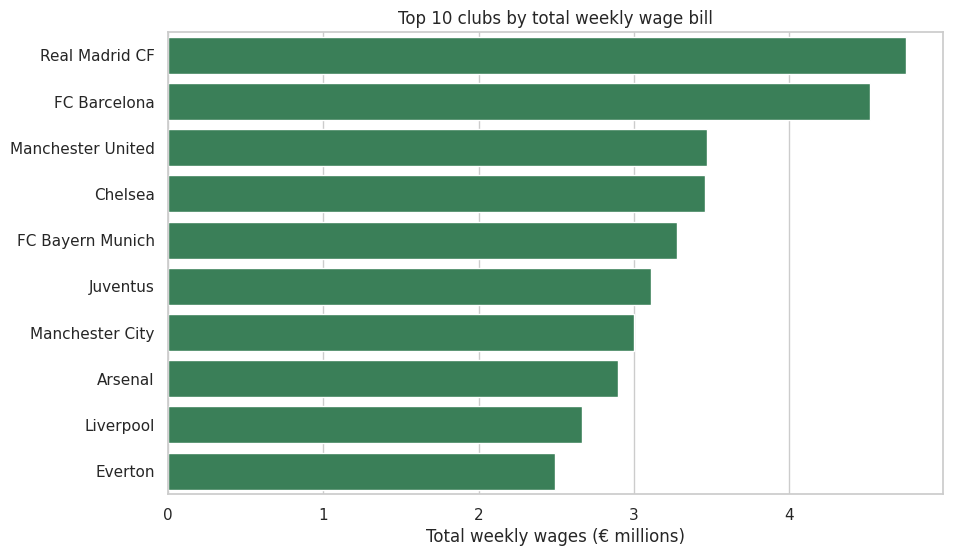

In [17]:
#ST10365068
plt.figure(figsize=(10, 6))
sns.barplot(x=top_wage_clubs["Total_Weekly_Wage"] / 1_000_000, y=top_wage_clubs.index, color="seagreen")
plt.title("Top 10 clubs by total weekly wage bill")
plt.xlabel("Total weekly wages (€ millions)")
plt.ylabel("")
plt.show()

In [18]:
#ST10365068
top_paid = df.sort_values(by="Wage_EUR", ascending=False)[["Name", "Age", "Club", "Nationality", "Overall", "Wage"]].head(10)
top_paid

,Name,Age,Club,Nationality,Overall,Wage
0,L. Messi,30,FC Barcelona,Argentina,93,€565K
1,Cristiano Ronaldo,32,Real Madrid CF,Portugal,94,€565K
3,L. Suárez,30,FC Barcelona,Uruguay,92,€510K
30,G. Bale,27,Real Madrid CF,Wales,89,€370K
7,R. Lewandowski,28,FC Bayern Munich,Poland,91,€355K
16,L. Modrić,31,Real Madrid CF,Croatia,89,€340K
9,T. Kroos,27,Real Madrid CF,Germany,90,€340K
18,S. Agüero,29,Manchester City,Argentina,89,€325K
12,Sergio Ramos,31,Real Madrid CF,Spain,90,€310K
8,E. Hazard,26,Chelsea,Belgium,90,€295K


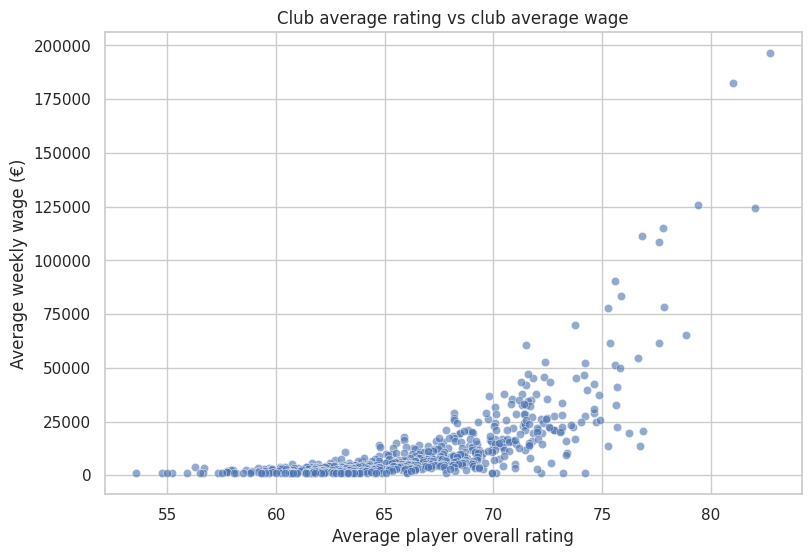

Correlation: 0.68


In [19]:
#ST10365068
plt.figure(figsize=(9, 6))
sns.scatterplot(data=club_wages, x="Average_Overall", y="Average_Wage", alpha=0.6)
plt.title("Club average rating vs club average wage")
plt.xlabel("Average player overall rating")
plt.ylabel("Average weekly wage (€)")
plt.show()

print("Correlation:", round(club_wages["Average_Overall"].corr(club_wages["Average_Wage"]), 2))

## 8. Group by nationality

In [20]:
#ST10365068
nationality_counts = df.groupby("Nationality")["Name"].count().sort_values(ascending=False)
print("Number of nationalities:", nationality_counts.size)
nationality_counts.head(10)

Number of nationalities: 162


Nationality
England        1428
Germany        1079
Spain           920
France          899
Argentina       781
Brazil          721
Italy           702
Colombia        456
Netherlands     398
Japan           393
Name: Name, dtype: int64

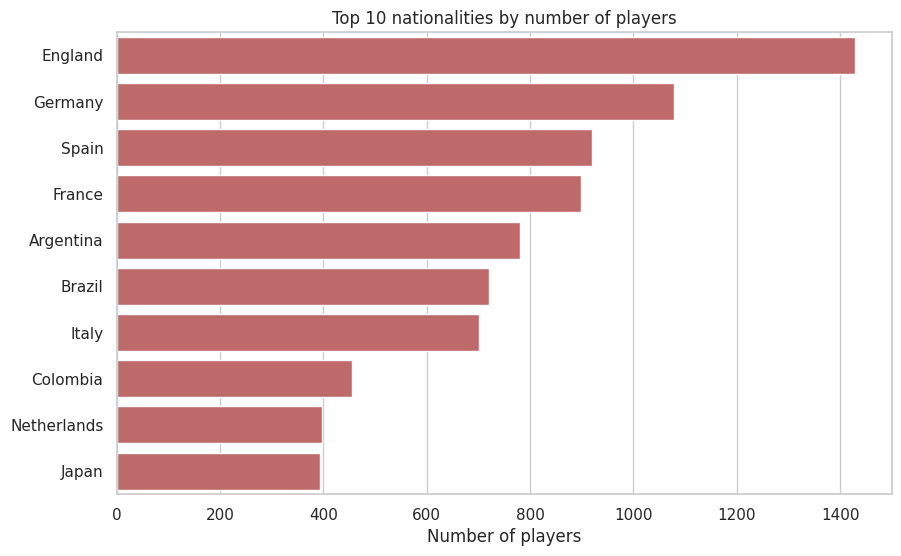

In [21]:
#ST10365068
plt.figure(figsize=(10, 6))
sns.barplot(x=nationality_counts.head(10).values, y=nationality_counts.head(10).index, color="indianred")
plt.title("Top 10 nationalities by number of players")
plt.xlabel("Number of players")
plt.ylabel("")
plt.show()

In [22]:
#ST10365068
# average quality per nationality (only countries with at least 100 players, to avoid tiny samples)
nat_stats = (df.groupby("Nationality")
               .agg(Players=("Name", "count"),
                    Average_Overall=("Overall", "mean"),
                    Average_Age=("Age", "mean"),
                    Average_Wage=("Wage_EUR", "mean")))
nat_stats[nat_stats["Players"] >= 100].sort_values(by="Average_Overall", ascending=False).head(10).round(1)

,Players,Average_Overall,Average_Age,Average_Wage
Nationality,,,,
Chile,100,71.4,28.3,15940.0
Brazil,721,71.2,27.3,19740.6
Portugal,320,71.0,25.4,16153.1
Serbia,120,70.6,25.5,18375.0
Spain,920,70.4,25.3,19971.7
Uruguay,122,70.4,25.8,20450.8
Senegal,117,68.6,25.1,17641.0
Belgium,253,68.5,24.1,19585.0
Argentina,781,68.4,26.1,13882.2


In [23]:
#ST10365068
# South African players in the dataset
df[df["Nationality"] == "South Africa"][["Name", "Age", "Club", "Overall", "Wage"]].sort_values(by="Overall", ascending=False)

,Name,Age,Club,Overall,Wage
986,I. Khune,30,Kaizer Chiefs,77,€1K
1202,S. Tshabalala,32,Kaizer Chiefs,76,€1K
2210,P. Tau,23,NaN,76,€0
1511,T. Hlatshwayo,27,NaN,75,€0
1643,B. Zungu,24,Amiens SC Football,75,€17K
2308,T. Matlaba,29,Orlando Pirates,74,€1K
2450,T. Serero,27,Vitesse,74,€13K
3076,K. Mokotjo,26,Brentford,74,€42K
3105,B. Parker,31,Kaizer Chiefs,72,€1K
3263,M. Makola,31,Orlando Pirates,72,€1K


## 9. Age vs rating

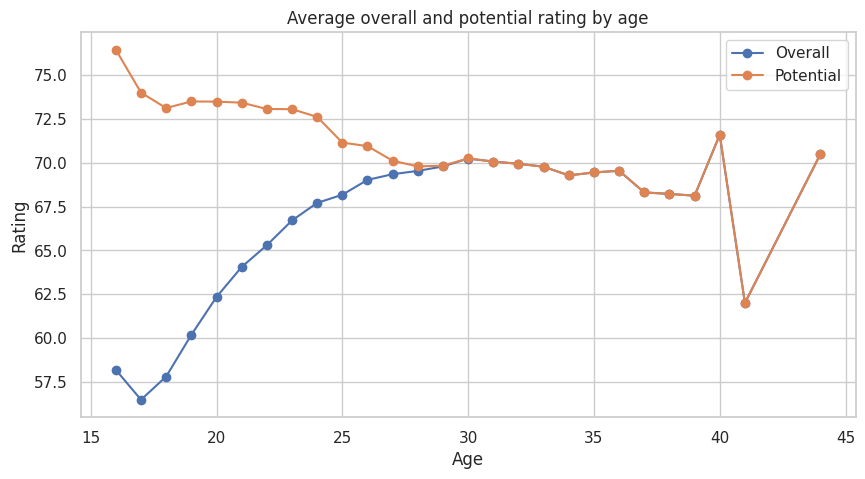

In [24]:
#ST10365068
age_rating = df.groupby("Age")[["Overall", "Potential"]].mean()

plt.figure(figsize=(10, 5))
plt.plot(age_rating.index, age_rating["Overall"], label="Overall", marker="o")
plt.plot(age_rating.index, age_rating["Potential"], label="Potential", marker="o")
plt.title("Average overall and potential rating by age")
plt.xlabel("Age")
plt.ylabel("Rating")
plt.legend()
plt.show()

## 10. Conclusion
**Data quality**
- The dataset holds 15 405 rows; 87 were exact duplicates of the same player and were removed, leaving **15 318 unique players**.
- Every player has an age, but **172 players (1.12%) have no club** – these are free agents. They were dropped from the club-based analysis so that every remaining player has both an age and a club.

**Age**
- The youngest players are **16** (e.g. L. Geertruida – Feyenoord, E. Håland – Molde FK, A. Gomes – Manchester United) and the oldest are **44** (E. El Hadary – Al Taawoun, O. Pérez – Pachuca).
- The average and median age are both about **25**. Average overall rating keeps rising until around age 30 and then levels off, while *potential* is highest for young players – showing that clubs value young players for their room to grow.

**Filtering a team**
- Filtering on Manchester United returns a squad of 32 players with an average age of 24.3. The `get_team()` function can be reused for any club.

**Wages**
- **Real Madrid (€4.75M per week)** and **FC Barcelona (€4.52M)** have the highest wage bills, followed by Manchester United, Chelsea and Bayern Munich. Six of the top ten are English Premier League clubs.
- Cristiano Ronaldo and Lionel Messi are the highest-paid players (€565K per week each).
- There is a **strong positive correlation (r ≈ 0.68)** between a club's average player rating and its average wage – better squads cost more.

**Nationality**
- Players come from **162 countries**. England (1 428), Germany (1 079) and Spain (920) supply the most players, largely because their domestic leagues are well represented in the game.
- By quality (countries with at least 100 players), **Chile, Brazil and Portugal** have the highest average overall ratings, so having many players does not mean having the best players.

**Limitations**
- Wages and values are FIFA 18 game estimates, not real contracts, and some leagues (e.g. the South African PSL) show token wages of €1K.
- The analysis is descriptive; it shows relationships (such as rating vs wage) but does not prove cause and effect.